In [1]:
# 导入数据，digit手写数字识别
import pandas as pd
data = pd.read_csv("./digit.csv")
data

/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41996,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41997,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41998,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [2]:
X = data.iloc[:, 1:]
y = data.iloc[:, 0]
X.shape

(42000, 784)

In [3]:
from sklearn.feature_selection import VarianceThreshold
selector = VarianceThreshold()
X_var0 = selector.fit_transform(X)

X_var0.shape

(42000, 708)

In [4]:
pd.DataFrame(X_var0).head()

,0,1,2,3,4,5,6,7,8,9,...,698,699,700,701,702,703,704,705,706,707
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [10]:
# 中位数方差过滤
import numpy as np

X_fsvar = VarianceThreshold(np.median(X.var().values)).fit_transform(X)
X_fsvar.shape

(42000, 392)

In [11]:
# 二分类问题下方差过滤
X_bvar = VarianceThreshold(0.8 * (1-0.8)).fit_transform(X)
X_bvar.shape

(42000, 685)

In [13]:
# KNN在不同方差过滤效果下的对比
from sklearn.ensemble import RandomForestClassifier as RFC
from sklearn.neighbors import KNeighborsClassifier as KNN
from sklearn.model_selection import cross_val_score
import numpy as np
import pandas as pd

X = data.iloc[:, 1:]
y = data.iloc[:, 0]

X_fsvar = VarianceThreshold(np.median(X.var().values)).fit_transform(X)
# X是未经过方差过滤前的全部特征
# X_fsvar是经过方差过滤后的一半特征

In [ ]:
# KNN算法在方差过滤前的表现
cross_val_score(KNN(), X, y, cv=5).mean()
# 0.9658

In [ ]:
%%timeit
cross_val_score(KNN(), X, y, cv=5).mean()
# 33min58s +- 43.9s per loop

In [ ]:
# KNN算法在方差过滤后的表现
cross_val_score(KNN(), X_fsvar, y, cv=5).mean()
# 0.9660

In [ ]:
%%timeit
cross_val_score(KNN(), X_fsvar, y, cv=5).mean()
# 20min +- 4min55s per loop

In [14]:
# 随机森林算法在方差过滤前的表现
cross_val_score(RFC(n_estimators=10, random_state=0), X, y, cv=5).mean()
# 0.9371

0.9371190476190476

In [15]:
%%timeit
cross_val_score(RFC(n_estimators=10, random_state=0), X, y, cv=5).mean()
# 

7.45 s ± 31.9 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [16]:
# 随机森林算法在方差过滤后的表现
cross_val_score(RFC(n_estimators=10, random_state=0), X_fsvar, y, cv=5).mean()
# 0.9393

0.9393333333333335

In [17]:
%%timeit
cross_val_score(RFC(n_estimators=10, random_state=0), X_fsvar, y, cv=5).mean()

7.33 s ± 66 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [19]:
X_fsvar.shape

(42000, 392)

In [18]:
# 相关性过滤：卡方过滤
from sklearn.ensemble import RandomForestClassifier as RFC
from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2

X_fschi = SelectKBest(chi2, k=300).fit_transform(X_fsvar, y)
X_fschi.shape

(42000, 300)

In [20]:
cross_val_score(RFC(n_estimators=10, random_state=0), X_fschi, y, cv=5).mean()

0.9337380952380953

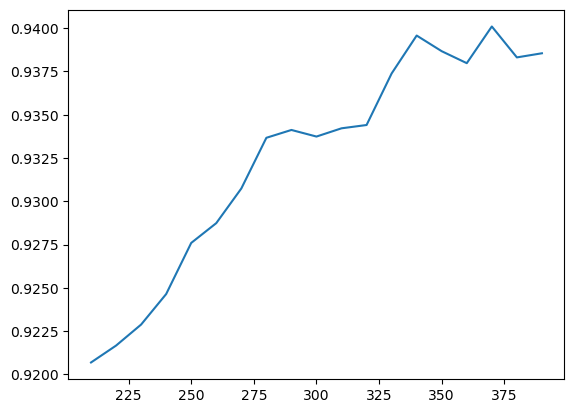

In [21]:
# 画chi2的K超参数的学习曲线
import matplotlib.pyplot as plt

score = []
for i in range(390, 200, -10):
    X_fschi = SelectKBest(chi2, k=i).fit_transform(X_fsvar, y)
    once = cross_val_score(RFC(n_estimators=10, random_state=0), X_fschi, y, cv=5).mean()
    score.append(once)

plt.plot(range(390, 200, -10), score)
plt.show()

In [23]:
# 通过chivalue和pvalue来确定K的取值
chivalue, pvalues_chi =  chi2(X_fsvar, y)

In [24]:
chivalue

array([ 945664.84392645, 1244766.05139167, 1554872.30384529,
       1834161.78305348, 1903618.94085299, 1845226.62427203,
       1602117.23307541,  708535.17489839,  974050.2051372 ,
       1188092.19961933, 1319151.4346704 , 1397847.88367963,
       1433554.26798019, 1429043.15373436, 1332663.17213408,
       1101423.25372263,  809989.56940487,  519266.71772285,
        285681.88297156,  191589.23696469,  902883.12552642,
       1237265.16042376, 1503477.73699159, 1625807.41495546,
       1630206.9092292 , 1630597.02883808, 1633456.72909668,
       1610816.75571233, 1483382.4954389 , 1256290.15747943,
        951236.16176823,  693192.66191749,  532386.96220362,
        504617.38933716,  575090.36046245,  501025.03733246,
        802341.10683196, 1078344.87244063, 1226540.98318705,
       1269945.07968834, 1221758.57688811, 1146535.17810244,
       1080657.20185306, 1079065.30979138, 1092222.70610035,
       1064908.45385719, 1023327.00231069,  974163.15420168,
        918857.12860619,

In [25]:
pvalues_chi

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [28]:
# chi2检验根据p值来确定K的取值
k = chivalue.shape[0] - (pvalues_chi > 0.05).sum()

X_fschi = SelectKBest(chi2, k=k).fit_transform(X_fsvar, y)
cross_val_score(RFC(n_estimators=10, random_state=0), X_fschi, y, cv=5).mean()

0.9393333333333335

In [29]:
# F检验根据P值来确定K的取值
from sklearn.feature_selection import f_classif

F, pvalues_f = f_classif(X_fsvar, y)

In [32]:
k = F.shape[0] - (pvalues_f > 0.05).sum()
X_fsF = SelectKBest(chi2, k=k).fit_transform(X_fsvar, y)
cross_val_score(RFC(n_estimators=10, random_state=0), X_fsF, y, cv=5).mean()

0.9393333333333335

In [33]:
# 互信息法根据取值0、1来确定K的取值
from sklearn.feature_selection import mutual_info_classif as MIC
result = MIC(X_fsvar, y)
result

array([0.04813428, 0.0656817 , 0.07556179, 0.08666141, 0.08963377,
       0.0854946 , 0.06743095, 0.03714998, 0.05305662, 0.0694369 ,
       0.08793459, 0.09728101, 0.10892462, 0.11592189, 0.10575051,
       0.08630979, 0.0629863 , 0.03859541, 0.02518728, 0.01628137,
       0.05283451, 0.06532047, 0.095391  , 0.10881588, 0.12170136,
       0.1378907 , 0.1631117 , 0.15968032, 0.14148733, 0.11843475,
       0.0869512 , 0.06413668, 0.04751276, 0.03883291, 0.04065767,
       0.0264455 , 0.0414715 , 0.06071774, 0.07353515, 0.09141955,
       0.09736286, 0.10021261, 0.11045567, 0.1171164 , 0.12163649,
       0.12348527, 0.11122396, 0.08550595, 0.06681873, 0.06578522,
       0.05467568, 0.04699528, 0.04752559, 0.0311664 , 0.04818121,
       0.05005143, 0.05490477, 0.0548193 , 0.05950881, 0.05660733,
       0.06432353, 0.07553538, 0.07456694, 0.07587895, 0.07417678,
       0.07578268, 0.07678341, 0.07190059, 0.05957878, 0.05353345,
       0.05495082, 0.0393129 , 0.04278096, 0.04649671, 0.05162

In [34]:
k = result.shape[0] - sum(result<=0)
X_fsmic = SelectKBest(MIC, k=k).fit_transform(X_fsvar, y)
cross_val_score(RFC(n_estimators=10, random_state=0), X_fsmic, y, cv=5).mean()

0.9393333333333335

In [36]:
# 嵌入法模型评估，筛选特征
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier as RFC

RFC_ = RFC(n_estimators=10, random_state=0)

X_embedded = SelectFromModel(RFC_, threshold=0.005).fit_transform(X, y)
X_embedded.shape

(42000, 45)

In [ ]:
# 通过学习曲线来寻找threshold
import numpy as np
import matplotlib.pyplot as plt

threshold = np.linspace(0, (RFC_.fit(X, y).feature_importances_).max(), 20)

score = []
for i in threshold:
    X_embedded = SelectFromModel(RFC_, threshold=i).fit_transform(X, y)
    once = cross_val_score(RFC_, X_embedded, y, cv=5).mean()
    score.append(once)

plt.plot(threshold, score)
plt.show()

In [41]:
X_embedded = SelectFromModel(RFC_, threshold=0.00067).fit_transform(X, y)
X_embedded.shape

(42000, 329)

In [42]:
cross_val_score(RFC_, X_embedded, y, cv=5).mean()

0.9386190476190477

In [ ]:
# 精细化调参
score2 = []
for i in np.linspace(0, 0.00134, 20):
    X_embedded = SelectFromModel(RFC_, threshold=i).fit_transform(X, y)
    once = cross_val_score(RFC_, X_embedded, y, cv=5).mean()
    score2.append(once)

plt.figure(figsize=[20, 5])
plt.plot(np.linspace(0, 0.00134, 20), score2)
plt.xticks(np.linspace(0, 0.00134, 20))
plt.show()

In [43]:
# 选取精细化调参表现最好的参数
X_embedded = SelectFromModel(RFC_, threshold=0.000564).fit_transform(X, y)
X_embedded.shape
cross_val_score(RFC_, X_embedded, y, cv=5).mean()

0.9390476190476191

In [44]:
cross_val_score(RFC(n_estimators=100, random_state=0), X_embedded, y, cv=5).mean()

0.9633333333333333

In [45]:
# 包装法
from sklearn.feature_selection import RFE
RFC_ = RFC(n_estimators=10, random_state=0)
selector = RFE(RFC_, n_features_to_select=340, step=50).fit(X, y)

selector.support_

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False,  True,  True, False,
        True,  True,  True,  True,  True, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False,  True,  True,  True,
        True,  True,

In [46]:
selector.support_.sum()

340

In [47]:
selector.ranking_

array([10,  9,  8,  7,  6,  6,  6,  7,  7,  7,  6,  6,  6,  7,  7,  6,  6,
        6,  7,  7,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,  6,
        6,  6,  6,  6,  6,  6,  6,  6,  6,  7,  6,  7,  7,  7,  7,  7,  7,
        7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  6,  5,  5,  4,
        5,  4,  3,  4,  5,  4,  5,  5,  3,  5,  6,  7,  8,  8,  8,  8,  8,
        8,  8,  8,  8,  8,  7,  5,  4,  4,  4,  2,  1,  1,  2,  1,  1,  1,
        1,  1,  2,  4,  4,  6,  8,  7,  8,  9,  9,  9,  9,  9,  9,  5,  5,
        5,  3,  1,  2,  1,  1,  1,  1,  1,  1,  1,  1,  1,  3,  2,  4,  4,
        6,  5,  8,  9, 10, 10, 10, 10,  8,  5,  4,  3,  2,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  3,  5,  6, 10, 10, 10, 10,
       10,  8,  4,  3,  3,  2,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  2,  5,  6, 10, 10, 10,  9,  6,  4,  3,  2,  2,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        3,  6, 10, 10, 10

In [48]:
X_wrapper = selector.transform(X)

cross_val_score(RFC_, X_wrapper, y, cv=5).mean()

0.9388571428571428

In [ ]:
# 包装法下的学习曲线
score = []
for i in range(1, 751, 50):
    X_wrapper = RFE(RFC_, n_features_to_select=i, step=50).fit(X, y)
    once = cross_val_score(RFC_, X_wrapper, y, cv=5).mean()
    score.append(once)
plt.figure(figsize=[20, 5])
plt.plot(range(1, 751, 50), score)
plt.xticks(range(1, 751, 50))
plt.show()